# Part 2: Logistic Regression from Scratch
## 1. Dataset selection and justification

The purpose of this analysis is to develop a logistic regression algorithm
from scratch to classify books according to their bestseller status.

The study will use a reproducible random sample of 20,000 book records that exceeds the required 10,000 observations
from the Amazon product metadata dataset hosted by Stanford SNAP.
The source contains book titles, sales ranks, category information and
review summaries (Stanford SNAP, n.d.).

Each observation represents a book product or edition, identified by an
Amazon Standard Identification Number (ASIN). Individual customer reviews
are not treated as separate book observations.

| Criterion | Evaluation |
|---|---|
| Size | The documented book population exceeds 10,000 records. The actual imported and cleaned counts will be verified using Spark. |
| Relevance | Sales rank provides a sales-related basis for creating a binary outcome. |
| Provenance | The source is an academic repository with a documented format and associated research. |
| Completeness | Missing titles, identifiers, ranks and review summaries must be investigated. |
| Validity | Rank must be positive, review counts non-negative and average ratings within the documented rating range. |
| Uniqueness | Duplicate ASINs and repeated titles must be investigated because different editions may represent the same work. |
| Timeliness | The data are old and may not represent current publishing markets. |
| Representativeness | An Amazon catalogue crawl does not represent every publisher, country or distribution channel. |
| Predictive suitability | Suitable for a historical rank-based classification exercise, but insufficient for validating future sales forecasts. |

The dataset was preferred over a ratings-only dataset because customer
satisfaction and sales performance are different outcomes. However, sales
rank does not provide the number of copies sold.

The associated research is described by Leskovec, Adamic and Huberman
(2007).

## 2. Analysis Plan


### 2.1 Exploratory data analysis and data cleaning

The first stage is about getting to know the dataset (its structure, its quality and its main features) before any modelling begins.

| Planned activity | Why it matters |
|---|---|
| Confirm the number of records and columns | Make sure the dataset meets the minimum of 10,000 observations and get a feel for its structure. |
| Inspect the Spark schema and sample records | Spot wrong data types, unexpected values and problems caused by loading the CSV. |
| Check for missing values | Find out which variables are incomplete and decide how to handle them. |
| Check for duplicate ASINs and repeated titles | Catch duplicate products and different editions of the same book. |
| Validate numerical values | Check that sales ranks are positive, review counts are not negative and ratings sit within the expected range. |
| Look at numerical summaries and distributions | See where the data is skewed, find unusual observations and compare typical values with extreme ones. |
| Look at target-class frequencies | Work out what share of books are bestsellers and what share are not. |
| Explore relationships with the target | See whether title characteristics and subject categories differ between the two classes. |

### 2.2 Feature engineering and selection

When choosing features, I will focus on relevance, ease of interpretation and whether the information would actually be available at the point where a prediction is made.

The starting predictors will be:

- The number of characters in a book's title.
- The number of words in its title.
- The number of categories the book belongs to.
- Indicators for selected broad subject categories.

I will consider a log transformation of the category count to reduce skewness, and subject categories will be turned into numerical indicator variables.

These variables will be left out of the main model:

| Excluded variable | Reason |
|---|---|
| Sales rank | It directly defines the target, so it would give the model the answer. |
| ASIN and product ID | They identify products and say nothing about how well a book sells. |
| Exact title identity | It could lead the model to memorise particular books. Title-length features will be used instead. |
| Review count and average rating | They aren't available for unpublished books and may simply reflect sales that have already happened. |

### 2.3 Data partitioning and preprocessing

The data will be split roughly as follows:

- 60% for training.
- 20% for validation.
- 20% for final testing.

### 2.4 Logistic regression implementation and training

I will write the logistic regression in NumPy and not use a ready-made classifier.

The implementation will cover these steps:

1. Setting the starting coefficients and intercept.
2. Calculating a linear score for each book.
3. Applying the sigmoid function to turn scores into probabilities.
4. Calculating the binary cross-entropy loss.
5. Calculating the gradients of the loss.
6. Updating the coefficients with gradient descent.
7. Turning probabilities into class predictions.

The maths will follow the standard logistic regression approach described by James et al. (2023). I will also run a numerical gradient check to confirm that the analytical gradient has been coded correctly.

These are the training settings I plan to try:

| Hyperparameter | Planned values or rule | Justification |
|---|---|---|
| Learning rate | 0.1 and 0.3 | Compare smaller and larger update steps. |
| Maximum gradient updates | 600 | Set a clear limit on computation. |
| L2 regularisation | 0 and 0.01 | Compare a model with no penalty against one that discourages large coefficients. |
| Initial coefficients | Zero | A simple starting point that is easy to reproduce. |
| Early-stopping tolerance | Loss change below 0.00000001 for ten updates in a row | Stop once the training objective has practically stopped changing. |
| Initial classification threshold | 0.5 | A conventional starting point before I choose a threshold using the validation set. |

### 2.5 Model evaluation and interpretation

I will judge the model using several measures that complement each other. Accuracy alone won't decide whether the model succeeds, because the two classes may be imbalanced.

| Evaluation measure | How it will be read |
|---|---|
| Average precision | The main measure. It shows how well the model ranks positive cases while taking precision into account across different recall levels. |
| Precision | Of the books flagged as bestsellers, the share that really meet the target definition. |
| Recall | Of the actual bestsellers, the share the model manages to find. |
| F1-score | A single summary that gives precision and recall equal weight. |
| Balanced accuracy | A measure that treats both classes as equally important. |
| ROC-AUC | A supporting measure of how well the model separates the classes. |
| Log loss | A check on how good the predicted probabilities are. |
| Confusion matrix | The counts of true positives, true negatives, false positives and false negatives. |

### 2.6 Retraining and improvement strategy

The first model will use a learning rate of 0.1 and no L2 regularisation. I will then try other configurations to see whether changing the learning rate or adding regularisation improves validation performance.

For each comparison, I will record:

- The parameter changes I made.
- The reason for each change.
- How the training loss behaved differently.
- How validation average precision and log loss changed.
- Any trade-offs between precision and recall.

### 2.7 Reporting and communication

The final client report will cover:

1. The business objective and the working definition of a bestseller.
2. The dataset source, sample size, suitability and limitations.
3. The main data-quality issues and cleaning decisions.
4. EDA findings, backed by clearly labelled visualisations.
5. Feature-engineering and feature-selection decisions.
6. The from-scratch implementation and the chosen training settings.
7. Comparisons between the initial and alternative models.
8. Final test metrics and what they mean for the business.
9. Conclusions, limitations and recommendations.

## 3a) Exploratory Data Analysis
### Loading and Inspecting the dataset

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Create the Spark session used for the exploratory analysis.
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("Book_Bestseller_EDA")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.9


In [2]:
# Keep ASIN as text so identifiers retain any leading zeros.
# Give numerical columns explicit types rather than guessing them.
schema = """
    asin STRING,
    title STRING,
    salesrank LONG,
    category_count INTEGER,
    review_count LONG,
    average_rating DOUBLE,
    category_paths STRING
"""

books = (
    spark.read
    .option("header", True)
    .option("multiLine", True)
    .option("quote", '"')
    .option("escape", '"')
    .option("mode", "FAILFAST")
    .schema(schema)
    .csv("Amazon_Books_20000.csv")
    .cache()
)

print("Dataset loaded.")

Dataset loaded.


In [3]:
# Check the dataset dimensions.
record_count = books.count()
column_count = len(books.columns)

print("Number of records:", record_count)
print("Number of columns:", column_count)

# Confirm that the assignment's minimum requirement is met.
assert record_count >= 10000, "The dataset has fewer than 10,000 records."

# Display the column names and their data types.
print("\nColumn names:")
print(books.columns)

print("\nDataset schema:")
books.printSchema()

# Inspect a few records without printing long category descriptions.
books.select(
    "asin",
    "title",
    "salesrank",
    "category_count",
    "review_count",
    "average_rating"
).show(5, truncate=50)

Number of records: 20000
Number of columns: 7

Column names:
['asin', 'title', 'salesrank', 'category_count', 'review_count', 'average_rating', 'category_paths']

Dataset schema:
root
 |-- asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- salesrank: long (nullable = true)
 |-- category_count: integer (nullable = true)
 |-- review_count: long (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- category_paths: string (nullable = true)

+----------+--------------------------------------------------+---------+--------------+------------+--------------+
|      asin|                                             title|salesrank|category_count|review_count|average_rating|
+----------+--------------------------------------------------+---------+--------------+------------+--------------+
|0001057170|                        CLASSIC CONNOLLY BOXED SET|   708137|             3|           2|           3.5|
|0001360841|            Bumpy Dog Helps Out (Toy Town 

### Initial dataset inspection

The dataset loaded into Spark without any problems. It contains **20,000 records and seven columns**, which comfortably meets the minimum requirement of 10,000 records. The schema stores identifiers and text as strings and the numerical variables as suitable numeric types.

The preview shows a few books with zero reviews and an average rating of zero. I will look into these during cleaning, because a zero rating may simply mean that nobody has reviewed the book yet, and not that customers were unhappy with it.

### Checking missing values and duplicates

In [4]:
# Count null values in every column.
missing_counts = books.select([
    F.sum(
        F.when(F.col(column).isNull(), 1).otherwise(0)
    ).alias(column)

    for column in books.columns
])

print("Missing values per column:")
missing_counts.show()

Missing values per column:
+----+-----+---------+--------------+------------+--------------+--------------+
|asin|title|salesrank|category_count|review_count|average_rating|category_paths|
+----+-----+---------+--------------+------------+--------------+--------------+
|   0|    0|        0|             0|           0|             0|           901|
+----+-----+---------+--------------+------------+--------------+--------------+



The null-value check found 901 missing values in `category_paths`, which is about 4.51% of the dataset. The other six columns had no nulls at all. Before deciding how to handle the incomplete category information, I will also check separately for blank text values.

In [5]:
# Count completely identical rows.
total_records = books.count()

duplicate_rows = (
    total_records - books.dropDuplicates().count()
)

print("Completely duplicate rows:", duplicate_rows)

# Find ASINs appearing more than once.
duplicate_asins = (
    books
    .filter(F.col("asin").isNotNull())
    .groupBy("asin")
    .count()
    .filter(F.col("count") > 1)
)

print("ASINs appearing more than once:", duplicate_asins.count())

duplicate_asins.show(10, truncate=False)

Completely duplicate rows: 0
ASINs appearing more than once: 0
+----+-----+
|asin|count|
+----+-----+
+----+-----+



There are no duplicates.

In [6]:
# Standardise case and spacing for the title comparison.
title_check = books.withColumn(
    "normalized_title",
    F.lower(
        F.trim(
            F.regexp_replace(
                F.col("title"),
                r"\s+",
                " "
            )
        )
    )
)

repeated_titles = (
    title_check
    .filter(
        F.col("normalized_title").isNotNull()
        & (F.col("normalized_title") != "")
    )
    .groupBy("normalized_title")
    .count()
    .filter(F.col("count") > 1)
    .orderBy(F.desc("count"))
)

print("Titles appearing more than once:", repeated_titles.count())

repeated_titles.show(10, truncate=60)

Titles appearing more than once: 75
+------------------------------------------------------------+-----+
|                                            normalized_title|count|
+------------------------------------------------------------+-----+
|weight watchers coach approach: how to motivate the "thin...|    2|
|                                                the wanderer|    2|
|  we're not monsters: teens speak out about teens in trouble|    2|
|                                                   the hours|    2|
|                                         the alpine obituary|    2|
|                                  annals of the former world|    2|
|                                              life of christ|    2|
|            a walk down the aisle: notes on a modern wedding|    2|
|                                                     journey|    2|
|                                                    the oath|    2|
+------------------------------------------------------------+-----

The check found 75 distinct normalised titles that appear more than once. These could be different editions of the same book, or unrelated books that happen to share a title, so I will not remove them automatically. To reduce the risk of leakage during model evaluation, books with identical normalised titles will be kept in the same data partition.

In [7]:
# Check numerical values against their expected ranges.
validity_checks = books.select(
    F.sum(
        F.when(F.col("salesrank") <= 0, 1).otherwise(0)
    ).alias("non_positive_salesrank"),

    F.sum(
        F.when(F.col("category_count") < 0, 1).otherwise(0)
    ).alias("negative_category_count"),

    F.sum(
        F.when(F.col("review_count") < 0, 1).otherwise(0)
    ).alias("negative_review_count"),

    F.sum(
        F.when(
            (F.col("average_rating") < 0)
            | (F.col("average_rating") > 5),
            1
        ).otherwise(0)
    ).alias("ratings_outside_0_to_5")
)

validity_checks.show(vertical=True)

-RECORD 0----------------------
 non_positive_salesrank  | 0   
 negative_category_count | 0   
 negative_review_count   | 0   
 ratings_outside_0_to_5  | 0   



The numerical checks turned up no sales ranks that were zero or negative, no negative category or review counts, and no ratings outside the 0–5 range, so none of these checks require any corrections. I will look at the zero ratings separately to find out whether they belong to books that simply have no reviews.

In [8]:
# Distinguish absent reviews from actual customer ratings.
review_checks = books.select(
    F.sum(
        F.when(F.col("review_count") == 0, 1).otherwise(0)
    ).alias("books_without_reviews"),

    F.sum(
        F.when(
            (F.col("review_count") == 0)
            & (F.col("average_rating") == 0),
            1
        ).otherwise(0)
    ).alias("no_reviews_and_zero_rating"),

    F.sum(
        F.when(
            (F.col("review_count") > 0)
            & (F.col("average_rating") == 0),
            1
        ).otherwise(0)
    ).alias("has_reviews_but_zero_rating"),

    F.sum(
        F.when(
            (F.col("review_count") == 0)
            & (F.col("average_rating") > 0),
            1
        ).otherwise(0)
    ).alias("no_reviews_but_positive_rating")
)

review_checks.show(vertical=True)

-RECORD 0------------------------------
 books_without_reviews          | 5756 
 no_reviews_and_zero_rating     | 5756 
 has_reviews_but_zero_rating    | 0    
 no_reviews_but_positive_rating | 0    



In total, 5,756 books (28.78%) have no reviews, and every one of them has an average rating of zero. I found no mismatches between having reviews and having a rating, so the zero ratings clearly mean that nobody has reviewed these books, not that customers rated them poorly. During cleaning, I will treat these zero ratings as missing rating information.

In [9]:
# Check whether missing category paths coincide with zero memberships.
books.groupBy(
    F.col("category_paths").isNull().alias("category_paths_missing")
).agg(
    F.count("*").alias("books"),
    F.min("category_count").alias("minimum_category_count"),
    F.max("category_count").alias("maximum_category_count")
).show()

+----------------------+-----+----------------------+----------------------+
|category_paths_missing|books|minimum_category_count|maximum_category_count|
+----------------------+-----+----------------------+----------------------+
|                 false|19099|                     1|                    23|
|                  true|  901|                     0|                     0|
+----------------------+-----+----------------------+----------------------+



All 901 books with missing category paths also have a category count of zero. The other 19,099 books belong to between 1 and 23 categories. This shows that the category information is simply absent for these books and not contradictory. I will keep these records and mark their category information as unavailable.

### Applying Data Cleaning Decisions

In [10]:
# Create a separate cleaned DataFrame.
clean_books = (
    books

    # Flag unavailable categories before replacing the missing text.
    .withColumn(
        "category_missing",
        (
            F.col("category_paths").isNull()
            | (F.trim(F.col("category_paths")) == "")
        ).cast("integer")
    )

    # Use an explicit label without inventing a subject category.
    .withColumn(
        "category_paths",
        F.when(
            F.col("category_missing") == 1,
            F.lit("Unknown")
        ).otherwise(F.col("category_paths"))
    )

    # Zero reviews means the average rating is unavailable.
    # Keep review_count at zero, but replace the corresponding rating.
    .withColumn(
        "average_rating",
        F.when(
            F.col("review_count") == 0,
            F.lit(None).cast("double")
        ).otherwise(F.col("average_rating"))
    )
)

# Repeated titles are retained because they may be different editions.
# No rows are removed in this step.
print("Original records:", books.count())
print("Records after cleaning:", clean_books.count())

Original records: 20000
Records after cleaning: 20000


In [11]:
clean_books.select(
    F.sum("category_missing").alias(
        "books_with_unavailable_categories"
    ),

    F.sum(
        F.when(
            F.col("average_rating").isNull(), 1
        ).otherwise(0)
    ).alias("missing_average_ratings"),

    F.sum(
        F.when(
            F.col("category_paths").isNull()
            | (F.trim(F.col("category_paths")) == ""),
            1
        ).otherwise(0)
    ).alias("remaining_null_or_blank_category_paths")
).show(vertical=True)

-RECORD 0--------------------------------------
 books_with_unavailable_categories      | 901  
 missing_average_ratings                | 5756 
 remaining_null_or_blank_category_paths | 0    



All 20,000 records were kept after cleaning. The 901 books with no category path were labelled "Unknown" and flagged with `category_missing`. No null or blank category paths remain, although the original category information for these books is still unavailable.

The 5,756 zero ratings belonging to books with no reviews were converted to null values, so that the absence of reviews isn't mistaken for poor ratings.

### Bestseller Target and Class Distribution

In [12]:
# Project definition:
# 1 = sales rank between 1 and 10,000 inclusive.
# 0 = sales rank above 10,000.
# Earlier checks confirmed that all sales ranks are positive.
clean_books = clean_books.withColumn(
    "bestseller",
    F.when(
        F.col("salesrank").between(1, 10000),
        1
    ).otherwise(0)
)

# Calculate class counts and percentages using Spark.
total_books = clean_books.count()

class_distribution = (
    clean_books
    .groupBy("bestseller")
    .agg(F.count("*").alias("book_count"))
    .withColumn(
        "percentage",
        F.round(
            F.col("book_count") / F.lit(total_books) * 100,
            2
        )
    )
    .orderBy("bestseller")
)

class_distribution.show()

+----------+----------+----------+
|bestseller|book_count|percentage|
+----------+----------+----------+
|         0|     19719|      98.6|
|         1|       281|      1.41|
+----------+----------+----------+



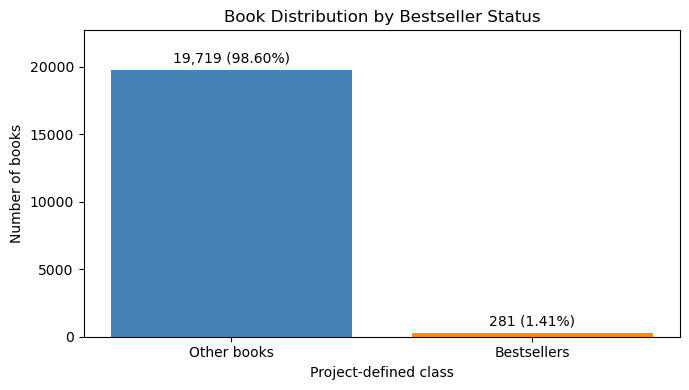

In [13]:
import matplotlib.pyplot as plt

# Collect only the two-row summary for plotting.
class_plot = class_distribution.toPandas()

labels = [
    "Other books" if value == 0 else "Bestsellers"
    for value in class_plot["bestseller"]
]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    labels,
    class_plot["book_count"],
    color=["steelblue", "darkorange"]
)

# Label each bar with its count and percentage.
for bar, count, percentage in zip(
    bars,
    class_plot["book_count"],
    class_plot["percentage"]
):
    ax.annotate(
        f"{count:,} ({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Book Distribution by Bestseller Status")
ax.set_xlabel("Project-defined class")
ax.set_ylabel("Number of books")
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

The chart shows a strong class imbalance, with roughly 70 non-bestsellers for every bestseller. Because of this, the model has to be judged on how well it picks out the minority bestseller class and not on its overall accuracy.

### Numerical Distributions and Potential Outliers

In [14]:
# Summarise the numerical variables after cleaning.
numerical_columns = [
    "salesrank",
    "category_count",
    "review_count",
    "average_rating"
]

clean_books.select(numerical_columns).summary(
    "count",
    "mean",
    "stddev",
    "min",
    "25%",
    "50%",
    "75%",
    "max"
).show()

+-------+-----------------+-----------------+-----------------+------------------+
|summary|        salesrank|   category_count|     review_count|    average_rating|
+-------+-----------------+-----------------+-----------------+------------------+
|  count|            20000|            20000|            20000|             14244|
|   mean|     623090.92285|           3.6237|         12.11745| 4.317572311148554|
| stddev|593634.2297615244|2.354925814920648|76.95842439559028|0.7521278131513569|
|    min|               64|                0|                0|               1.0|
|    25%|           200328|                2|                0|               4.0|
|    50%|           463924|                3|                2|               4.5|
|    75%|           845581|                5|                6|               5.0|
|    max|          3795269|               23|             4924|               5.0|
+-------+-----------------+-----------------+-----------------+------------------+



Review counts are heavily right-skewed. The mean is 12.12, but the median is only 2, and the maximum is 4,924. These extreme values need a closer look, but I will not remove them automatically.

Books have a median of 3 category memberships. Among the 14,244 books with available ratings, the mean rating is 4.32 and the median is 4.5. The remaining 5,756 books are left out of the rating summaries because they have no reviews.

In [15]:
# Compare typical values for bestsellers and other books.
class_summary = (
    clean_books
    .groupBy("bestseller")
    .agg(
        F.count("*").alias("books"),

        F.round(
            F.avg("review_count"), 2
        ).alias("mean_reviews"),

        F.expr(
            "percentile_approx(review_count, 0.5)"
        ).alias("median_reviews"),

        F.count("average_rating").alias("books_with_ratings"),

        F.round(
            F.avg("average_rating"), 2
        ).alias("mean_available_rating"),

        F.round(
            F.avg("category_count"), 2
        ).alias("mean_category_count")
    )
    .orderBy("bestseller")
)

class_summary.show()

+----------+-----+------------+--------------+------------------+---------------------+-------------------+
|bestseller|books|mean_reviews|median_reviews|books_with_ratings|mean_available_rating|mean_category_count|
+----------+-----+------------+--------------+------------------+---------------------+-------------------+
|         0|19719|       10.53|             2|             13968|                 4.32|               3.61|
|         1|  281|      123.62|            30|               276|                  4.3|               4.55|
+----------+-----+------------+--------------+------------------+---------------------+-------------------+



Bestsellers have far more reviews, with a median of 30 compared with just 2 for other books. Their average ratings, though, are almost the same: 4.30 for bestsellers and 4.32 for other books. Bestsellers also belong to more categories on average (4.55 versus 3.61).

These are descriptive associations and do not show cause and effect. The review variables will stay out of the main model, since they aren't available before a book is published.

In [16]:
# Inspect extreme review counts without automatically removing them.
clean_books.select(
    "title",
    "review_count",
    "average_rating",
    "salesrank",
    "bestseller"
).orderBy(
    F.desc("review_count")
).show(10, truncate=45)

+---------------------------------------------+------------+--------------+---------+----------+
|                                        title|review_count|average_rating|salesrank|bestseller|
+---------------------------------------------+------------+--------------+---------+----------+
|Harry Potter and the Goblet of Fire (Book ...|        4924|           5.0|      661|         1|
|                   Holes (Newbery Medal Book)|        2919|           4.5|     5925|         1|
|                                    The Giver|        2620|           4.5|    88213|         0|
|                    The Lovely Bones: A Novel|        2287|           4.0|    81053|         0|
|                                  Enders Game|        2167|           4.5|   991142|         0|
|The Path of Daggers : Book Eight of 'The W...|        1688|           3.0|    64934|         0|
|Rich Dad, Poor Dad: What the Rich Teach Th...|        1641|           4.0|    72776|         0|
|Rich Dad Poor Dad : What  the

The most-reviewed book has 4,924 reviews, yet only three of the ten most-reviewed records meet the project's definition of a bestseller. In this snapshot, then, a large number of reviews doesn't necessarily mean a sales rank within the top 10,000. I will keep these observations, because a high review count on its own is not proof of an error.

### Review and Category Distributions

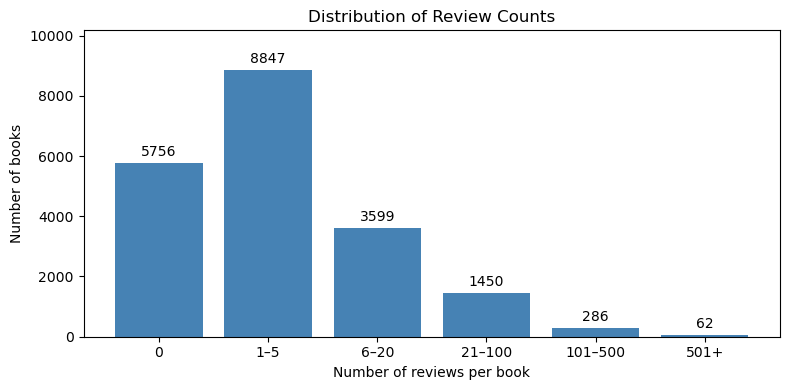

In [17]:
# Group review counts into readable ranges using Spark.
review_bins = (
    clean_books
    .withColumn(
        "review_range",
        F.when(F.col("review_count") == 0, "0")
        .when(F.col("review_count") <= 5, "1–5")
        .when(F.col("review_count") <= 20, "6–20")
        .when(F.col("review_count") <= 100, "21–100")
        .when(F.col("review_count") <= 500, "101–500")
        .otherwise("501+")
    )
    .groupBy("review_range")
    .count()
)

# Collect only the six aggregated rows for plotting.
review_order = ["0", "1–5", "6–20", "21–100", "101–500", "501+"]

review_plot = (
    review_bins.toPandas()
    .set_index("review_range")
    .reindex(review_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    review_plot.index,
    review_plot["count"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Distribution of Review Counts")
ax.set_xlabel("Number of reviews per book")
ax.set_ylabel("Number of books")
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

Most books have very few reviews: 14,603 of them (73.02%) have between zero and five. Only 62 books (0.31%) have more than 500 reviews. With so many books at the low end and just a small, highly reviewed tail, this backs up the earlier finding that review counts are strongly right-skewed.

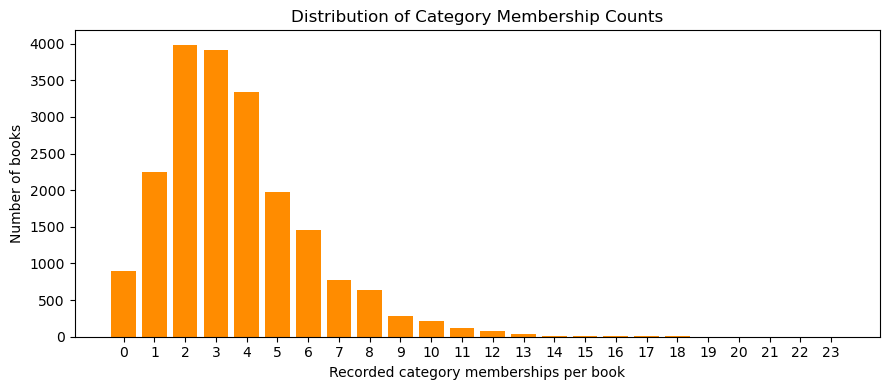

In [18]:
# Calculate the frequency of each category-membership count in Spark.
category_distribution = (
    clean_books
    .groupBy("category_count")
    .count()
    .orderBy("category_count")
)

category_plot = category_distribution.toPandas()

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    category_plot["category_count"],
    category_plot["count"],
    color="darkorange"
)

ax.set_title("Distribution of Category Membership Counts")
ax.set_xlabel("Recorded category memberships per book")
ax.set_ylabel("Number of books")

ax.set_xticks(
    range(int(category_plot["category_count"].max()) + 1)
)

plt.tight_layout()
plt.show()

Category membership counts are right-skewed. Most books belong to between two and four categories, and relatively few have high counts. This supports considering a log transformation before modelling. The 901 books with zero recorded memberships reflect category information that is simply unavailable, and they stay flagged separately.

### Title Characteristics and Subject Categories

In [19]:
# Create numerical features from book titles and category counts.
featured_books = (
    clean_books
    .withColumn(
        "title_chars",
        F.length(F.trim(F.col("title")))
    )
    .withColumn(
        "title_words",
        F.size(
            F.split(F.trim(F.col("title")), r"\s+")
        )
    )
    .withColumn(
        "log_categories",
        F.log1p(F.col("category_count"))
    )
)

# Compare title characteristics across the two classes.
featured_books.groupBy("bestseller").agg(
    F.count("*").alias("books"),

    F.round(
        F.avg("title_chars"), 2
    ).alias("mean_title_characters"),

    F.expr(
        "percentile_approx(title_chars, 0.5)"
    ).alias("median_title_characters"),

    F.round(
        F.avg("title_words"), 2
    ).alias("mean_title_words"),

    F.expr(
        "percentile_approx(title_words, 0.5)"
    ).alias("median_title_words")
).orderBy("bestseller").show()

+----------+-----+---------------------+-----------------------+----------------+------------------+
|bestseller|books|mean_title_characters|median_title_characters|mean_title_words|median_title_words|
+----------+-----+---------------------+-----------------------+----------------+------------------+
|         0|19719|                51.25|                     47|            7.88|                 7|
|         1|  281|                53.28|                     45|             8.5|                 7|
+----------+-----+---------------------+-----------------------+----------------+------------------+



Title characteristics look fairly similar across the two classes. Bestsellers have slightly longer titles on average (53.28 characters and 8.50 words) than other books (51.25 characters and 7.88 words), but both classes have a median of seven words. These summaries alone can't tell us whether title length is a useful predictor.

In [20]:
# Broad subject IDs in the source's Amazon category hierarchy.
subjects = {
    "fiction": 17,
    "children": 4,
    "business": 3,
    "religion": 22,
    "history": 9,
    "science": 75,
    "health": 10,
    "computers": 5
}

# A value of 1 means that the subject ID appears in the recorded paths.
# Unknown category records receive 0 for these flags, while the
# category_missing flag preserves their unavailable-information status.
for subject, category_id in subjects.items():
    featured_books = featured_books.withColumn(
        subject,
        F.col("category_paths")
        .contains(f"[{category_id}]")
        .cast("integer")
    )

In [21]:
# Convert the subject indicators into a long table for aggregation.
subject_rows = featured_books.select(
    "bestseller",
    F.explode(
        F.array(*[
            F.struct(
                F.lit(subject).alias("subject"),
                F.col(subject).alias("member")
            )
            for subject in subjects
        ])
    ).alias("subject_info")
)

subject_summary = (
    subject_rows
    .filter(F.col("subject_info.member") == 1)
    .groupBy(
        F.col("subject_info.subject").alias("subject")
    )
    .agg(
        F.count("*").alias("book_count"),
        F.sum("bestseller").alias("bestseller_count"),
        F.round(
            F.avg("bestseller") * 100, 2
        ).alias("bestseller_percentage")
    )
    .orderBy(F.desc("bestseller_percentage"))
)

subject_summary.show()

+---------+----------+----------------+---------------------+
|  subject|book_count|bestseller_count|bestseller_percentage|
+---------+----------+----------------+---------------------+
|   health|      1712|              63|                 3.68|
| business|      1436|              40|                 2.79|
| children|      2351|              42|                 1.79|
|  fiction|      2150|              36|                 1.67|
|  science|      1254|              18|                 1.44|
| religion|      2252|              24|                 1.07|
|  history|      1505|              10|                 0.66|
|computers|       923|               6|                 0.65|
+---------+----------+----------------+---------------------+



Among the selected subjects, health has the highest share of bestsellers (3.68%), followed by business (2.79%). Both are above the overall rate of roughly 1.41%. History (0.66%) and computers (0.65%) have the lowest shares. These differences are only descriptive, but they suggest that subject indicators could be useful predictors, though they don't show cause and effect. The subject groups overlap, so their counts shouldn't be added together.

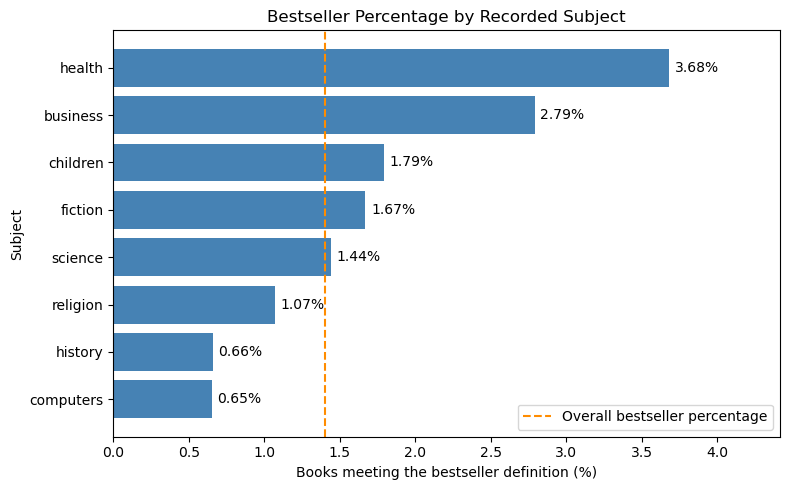

In [22]:
# Collect only the small subject-level summary.
subject_plot = (
    subject_summary.toPandas()
    .sort_values("bestseller_percentage")
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(
    subject_plot["subject"],
    subject_plot["bestseller_percentage"],
    color="steelblue"
)

ax.bar_label(bars, fmt="%.2f%%", padding=4)

# Show the overall bestseller percentage for comparison.
overall_percentage = (
    featured_books
    .agg(F.avg("bestseller") * 100)
    .first()[0]
)

ax.axvline(
    overall_percentage,
    color="darkorange",
    linestyle="--",
    label="Overall bestseller percentage"
)

ax.set_title("Bestseller Percentage by Recorded Subject")
ax.set_xlabel("Books meeting the bestseller definition (%)")
ax.set_ylabel("Subject")
ax.margins(x=0.2)
ax.legend()

plt.tight_layout()
plt.show()

The chart shows that health and business have clearly higher shares of bestsellers than the overall rate. Children and fiction are also above this benchmark, science is close to it, and religion, history and computers fall below it. These are only associations, and they do not mean that publishing in a particular subject will cause a book to become a bestseller.

## b) Data Partitioning and Feature Selection

### Creating Training, Validation and Test Sets

In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Candidate predictors exclude rank, identifiers and review information.
candidate_features = [
    "title_chars",
    "title_words",
    "log_categories",
    "category_missing",
    *subjects.keys()
]

# Keep identical normalized titles together when splitting.
featured_books = featured_books.withColumn(
    "title_group",
    F.lower(
        F.trim(
            F.regexp_replace("title", r"\s+", " ")
        )
    )
)

# Collect only the columns required for the NumPy model.
model_data = (
    featured_books
    .select(
        "asin",
        "title_group",
        "bestseller",
        *candidate_features
    )
    .orderBy("asin")
    .toPandas()
)

y = model_data["bestseller"].to_numpy(dtype=int)
groups = model_data["title_group"].to_numpy()

In [24]:
# Reserve approximately 20% of title groups for final testing.
first_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

trainval_index, test_index = next(
    first_split.split(model_data, y, groups)
)

# Reserve 25% of the remaining groups for validation:
# approximately 20% of the complete dataset.
second_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=43
)

train_relative, validation_relative = next(
    second_split.split(
        model_data.iloc[trainval_index],
        y[trainval_index],
        groups[trainval_index]
    )
)

train_index = trainval_index[train_relative]
validation_index = trainval_index[validation_relative]

In [25]:
# Check that no normalized title appears in two partitions.
for left, right in [
    (train_index, validation_index),
    (train_index, test_index),
    (validation_index, test_index)
]:
    assert set(groups[left]).isdisjoint(set(groups[right]))

# Check that every record belongs to exactly one partition.
all_indices = np.concatenate([
    train_index,
    validation_index,
    test_index
])

assert len(all_indices) == len(model_data)
assert len(np.unique(all_indices)) == len(model_data)

# Report class balance and confirm both classes are present.
split_results = []

for name, index in [
    ("Training", train_index),
    ("Validation", validation_index),
    ("Test", test_index)
]:
    assert len(np.unique(y[index])) == 2, (
        f"{name} does not contain both classes."
    )

    split_results.append({
        "partition": name,
        "records": len(index),
        "bestsellers": int(y[index].sum()),
        "other_books": int(len(index) - y[index].sum()),
        "bestseller_percentage": round(
            y[index].mean() * 100, 2
        )
    })

split_summary = pd.DataFrame(split_results)

display(split_summary)

print("Checks passed: all records assigned and no title-group overlap.")

,partition,records,bestsellers,other_books,bestseller_percentage
0,Training,11997,156,11841,1.30
1,Validation,3997,50,3947,1.25
2,Test,4006,75,3931,1.87


Checks passed: all records assigned and no title-group overlap.


The data was split into 11,997 training, 3,997 validation and 4,006 test records, which is very close to the planned 60/20/20 split. Every record was assigned to a partition, and no normalised title appears in more than one of them.

Both classes are present in every partition. The share of bestsellers varies from 1.25% in validation to 1.87% in the test set, because the grouped split was not stratified. I will keep this difference in mind when comparing validation and test metrics.

### Training-Only Feature Selection

In [26]:
# Use only training rows to make feature-selection decisions.
training_features = (
    model_data.iloc[train_index][candidate_features]
    .astype(float)
)

# Check for missing and non-finite predictor values.
feature_checks = pd.DataFrame({
    "missing_values": training_features.isna().sum(),
    "infinite_values": np.isinf(training_features).sum(),
    "unique_values": training_features.nunique()
})

display(feature_checks)

# Our engineered predictors should all be populated and finite.
assert np.isfinite(training_features.to_numpy()).all(), (
    "Missing or infinite predictor values require investigation."
)

# Identify predictors with no variation in the training set.
constant_features = feature_checks.index[
    feature_checks["unique_values"] <= 1
].tolist()

print("Constant features:", constant_features)

remaining_features = [
    feature for feature in candidate_features
    if feature not in constant_features
]

,missing_values,infinite_values,unique_values
title_chars,0,0,187
title_words,0,0,36
log_categories,0,0,20
category_missing,0,0,2
fiction,0,0,2
children,0,0,2
business,0,0,2
religion,0,0,2
history,0,0,2
science,0,0,2


Constant features: []


None of the 12 candidate predictors has missing or infinite values in the training set. Each one varies across observations, so there are no constant features to remove, and no imputation is needed for these predictors. Correlation checks will show whether any of them are redundant.

In [27]:
# Calculate Pearson correlations using training observations only.
training_correlations = training_features[
    remaining_features
].corr()

display(training_correlations.round(3))

# Keep the earlier feature in the declared candidate order
# when absolute correlation exceeds 0.90.
selected_features = []
removed_correlated = []

for feature in remaining_features:
    correlated_with = next(
        (
            retained
            for retained in selected_features
            if abs(
                training_correlations.loc[feature, retained]
            ) > 0.90
        ),
        None
    )

    if correlated_with is None:
        selected_features.append(feature)
    else:
        removed_correlated.append({
            "removed_feature": feature,
            "retained_feature": correlated_with,
            "correlation": training_correlations.loc[
                feature, correlated_with
            ]
        })

print("Features removed for high correlation:")

if removed_correlated:
    display(pd.DataFrame(removed_correlated))
else:
    print("None")

print("\nSelected features:")
print(selected_features)

print("\nNumber of selected features:", len(selected_features))

,title_chars,title_words,log_categories,category_missing,fiction,children,business,religion,history,science,health,computers
title_chars,1.000,0.947,0.098,-0.026,-0.149,-0.115,0.125,0.020,0.067,0.064,0.097,0.020
title_words,0.947,1.000,0.087,-0.031,-0.124,-0.082,0.101,0.045,0.086,0.035,0.105,-0.014
log_categories,0.098,0.087,1.000,-0.576,-0.014,0.046,0.307,-0.018,0.052,0.145,0.096,0.204
category_missing,-0.026,-0.031,-0.576,1.000,-0.079,-0.081,-0.061,-0.080,-0.064,-0.057,-0.068,-0.049
fiction,-0.149,-0.124,-0.014,-0.079,1.000,-0.075,-0.088,-0.066,-0.054,-0.077,-0.088,-0.077
children,-0.115,-0.082,0.046,-0.081,-0.075,1.000,-0.099,-0.103,-0.089,-0.084,-0.096,-0.077
business,0.125,0.101,0.307,-0.061,-0.088,-0.099,1.000,-0.079,-0.057,-0.030,-0.003,0.060
religion,0.020,0.045,-0.018,-0.080,-0.066,-0.103,-0.079,1.000,-0.037,-0.053,0.040,-0.079
history,0.067,0.086,0.052,-0.064,-0.054,-0.089,-0.057,-0.037,1.000,-0.010,-0.074,-0.060
science,0.064,0.035,0.145,-0.057,-0.077,-0.084,-0.030,-0.053,-0.010,1.000,0.017,-0.003


Features removed for high correlation:


,removed_feature,retained_feature,correlation
0,title_words,title_chars,0.947483



Selected features:
['title_chars', 'log_categories', 'category_missing', 'fiction', 'children', 'business', 'religion', 'history', 'science', 'health', 'computers']

Number of selected features: 11


Title word count and character count are strongly positively correlated, at about 0.947, which is above the 0.90 threshold. Following the feature order I set in advance, I removed title_words and kept title_charts to cut down on redundancy.

Eleven predictors remain, and no other pair of predictors went over the threshold. All of these decisions were based on the training data only.

### Feature Standardisation and Model Inputs

In [28]:
# Extract the selected predictors in a fixed column order.
X_selected = model_data[selected_features].to_numpy(dtype=float)

# Calculate scaling parameters using training observations only.
training_means = X_selected[train_index].mean(axis=0)
training_stds = X_selected[train_index].std(axis=0)

assert np.all(training_stds > 0), (
    "A selected predictor has zero training standard deviation."
)

# Apply the same training-based transformation to all partitions.
X_scaled = (
    X_selected - training_means
) / training_stds

assert np.isfinite(X_scaled).all(), (
    "The scaled predictors contain missing or infinite values."
)

# Verify training means are approximately zero and standard deviations one.
scaling_check = pd.DataFrame({
    "feature": selected_features,
    "original_training_mean": training_means,
    "original_training_std": training_stds,
    "scaled_training_mean": X_scaled[train_index].mean(axis=0),
    "scaled_training_std": X_scaled[train_index].std(axis=0)
})

display(scaling_check.round(4))

,feature,original_training_mean,original_training_std,scaled_training_mean,scaled_training_std
0,title_chars,51.1590,30.2287,-0.0,1.0
1,log_categories,1.3921,0.5388,0.0,1.0
2,category_missing,0.0473,0.2124,-0.0,1.0
3,fiction,0.1116,0.3149,-0.0,1.0
4,children,0.1178,0.3223,0.0,1.0
5,business,0.0705,0.2560,-0.0,1.0
6,religion,0.1139,0.3177,0.0,1.0
7,history,0.0758,0.2646,-0.0,1.0
8,science,0.0613,0.2400,0.0,1.0
9,health,0.0856,0.2798,-0.0,1.0


After standardisation, all 11 selected predictors have training means of roughly zero and standard deviations of one. The −0.0 values you see on screen are just a result of numerical rounding.

The scaling parameters were worked out from the training data alone and then applied unchanged to the validation and test data, so no information leaked in through preprocessing.

In [29]:
# Add a column of ones for the intercept.
# This column is added after scaling and is not standardised.
X = np.column_stack([
    np.ones(len(X_scaled)),
    X_scaled
])

# Keep predictor and outcome rows aligned.
X_train = X[train_index]
X_validation = X[validation_index]
X_test = X[test_index]

y_train = y[train_index]
y_validation = y[validation_index]
y_test = y[test_index]

print("Training predictor shape:", X_train.shape)
print("Validation predictor shape:", X_validation.shape)
print("Test predictor shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Validation target shape:", y_validation.shape)
print("Test target shape:", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_validation.shape[0] == len(y_validation)
assert X_test.shape[0] == len(y_test)

Training predictor shape: (11997, 12)
Validation predictor shape: (3997, 12)
Test predictor shape: (4006, 12)

Training target shape: (11997,)
Validation target shape: (3997,)
Test target shape: (4006,)


The training, validation and test predictor arrays hold 11,997, 3,997 and 4,006 records respectively. Each has 12 columns: the 11 selected predictors plus one intercept column. The target arrays have matching record counts, so the dimensions are compatible for training and evaluating the model.

## c) Logistic Regression from Scratch

### Implementing the Algorithm

In [30]:
# Standard logistic regression equations follow James et al. (2023).
# NumPy supplies array operations; no prebuilt classifier is used.

def sigmoid(scores):
    """Convert linear scores into probabilities."""
    # Separate positive and negative scores to avoid overflow.
    probabilities = np.empty_like(scores, dtype=float)
    positive = scores >= 0

    probabilities[positive] = (
        1 / (1 + np.exp(-scores[positive]))
    )

    exp_scores = np.exp(scores[~positive])

    probabilities[~positive] = (
        exp_scores / (1 + exp_scores)
    )

    return probabilities


def loss_and_gradient(X, y, weights, l2):
    """Calculate binary cross-entropy, L2 penalty and gradient."""
    scores = X @ weights
    probabilities = sigmoid(scores)

    # The first weight is the intercept and must not be penalised.
    penalty_weights = weights.copy()
    penalty_weights[0] = 0.0

    # Numerically stable binary cross-entropy.
    loss = (
        np.mean(np.logaddexp(0, scores) - y * scores)
        + 0.5 * l2 * np.sum(penalty_weights ** 2)
    )

    gradient = (
        X.T @ (probabilities - y) / len(y)
        + l2 * penalty_weights
    )

    return loss, gradient


class LogisticRegressionScratch:
    def __init__(
        self,
        learning_rate=0.1,
        iterations=600,
        l2=0.0,
        tolerance=1e-8
    ):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l2 = l2
        self.tolerance = tolerance

    def fit(self, X, y):
        # Initialise one weight per column, including the intercept.
        self.weights = np.zeros(X.shape[1])
        self.loss_history = []

        previous_loss = np.inf
        stable_steps = 0

        for step in range(self.iterations):
            loss, gradient = loss_and_gradient(
                X, y, self.weights, self.l2
            )

            if (
                not np.isfinite(loss)
                or not np.isfinite(gradient).all()
            ):
                raise ValueError(
                    "Non-finite loss or gradient during training."
                )

            # Record the objective before this update.
            self.loss_history.append(float(loss))

            # Move weights in the direction that reduces the loss.
            self.weights -= self.learning_rate * gradient

            if abs(previous_loss - loss) < self.tolerance:
                stable_steps += 1
            else:
                stable_steps = 0

            previous_loss = loss

            if stable_steps >= 10:
                break

        self.n_iterations = len(self.loss_history)

        # Calculate the objective at the final updated weights.
        self.final_loss, _ = loss_and_gradient(
            X, y, self.weights, self.l2
        )

        return self

    def predict_probability(self, X):
        return sigmoid(X @ self.weights)

    def predict(self, X, threshold=0.5):
        return (
            self.predict_probability(X) >= threshold
        ).astype(int)


print("Scratch logistic regression implementation defined.")

Scratch logistic regression implementation defined.


In [31]:
# Verify the analytical gradient using numerical differentiation.
# This small artificial dataset is only an implementation check.
rng = np.random.default_rng(42)

check_X = np.column_stack([
    np.ones(12),
    rng.normal(size=(12, 3))
])

check_y = rng.integers(0, 2, size=12)
check_weights = rng.normal(size=4)

epsilon = 1e-6

_, analytical_gradient = loss_and_gradient(
    check_X,
    check_y,
    check_weights,
    l2=0.01
)

numerical_gradient = np.zeros_like(check_weights)

for j in range(len(check_weights)):
    adjustment = np.zeros_like(check_weights)
    adjustment[j] = epsilon

    plus_loss, _ = loss_and_gradient(
        check_X,
        check_y,
        check_weights + adjustment,
        l2=0.01
    )

    minus_loss, _ = loss_and_gradient(
        check_X,
        check_y,
        check_weights - adjustment,
        l2=0.01
    )

    numerical_gradient[j] = (
        plus_loss - minus_loss
    ) / (2 * epsilon)

maximum_error = np.max(
    np.abs(analytical_gradient - numerical_gradient)
)

assert np.allclose(
    analytical_gradient,
    numerical_gradient,
    atol=1e-7,
    rtol=1e-5
), "Gradient check failed."

# Check the sigmoid at extreme inputs.
extreme_probabilities = sigmoid(
    np.array([-1000.0, 0.0, 1000.0])
)

assert np.isfinite(extreme_probabilities).all()
assert np.allclose(extreme_probabilities, [0.0, 0.5, 1.0])

print("Maximum absolute gradient difference:", maximum_error)
print("Gradient check passed.")
print("Sigmoid numerical-stability check passed.")

Maximum absolute gradient difference: 1.3550979782728234e-10
Gradient check passed.
Sigmoid numerical-stability check passed.


The gradient check passed. The largest absolute difference between the analytical and numerical gradients was about 1.36 × 10⁻¹⁰, which supports the gradient calculation being correct for the example I tested. The sigmoid also passed the check for stability with extreme inputs. These checks show that the implementation behaves correctly, but they say nothing about how well the model predicts.

### Training the Initial Model

In [32]:
# Initial configuration from the analysis plan.
initial_model = LogisticRegressionScratch(
    learning_rate=0.1,
    iterations=600,
    l2=0.0,
    tolerance=1e-8
)

# Learn coefficients using training data only.
initial_model.fit(X_train, y_train)

print("Gradient updates completed:", initial_model.n_iterations)
print("Initial training loss:", initial_model.loss_history[0])
print("Final training loss:", initial_model.final_loss)

if initial_model.n_iterations < initial_model.iterations:
    print("Stopping reason: training-loss tolerance reached.")
else:
    print("Stopping reason: maximum update budget reached.")

Gradient updates completed: 600
Initial training loss: 0.6931471805599453
Final training loss: 0.07088238837173207
Stopping reason: maximum update budget reached.


The initial model ran all 600 gradient updates, bringing the training loss down from 0.6931 to 0.0709. Training stopped because it hit the maximum number of updates and not because it met the early-stopping tolerance, so I can't say the model has converged. The validation metrics will show whether the model gives useful predictions beyond the majority-class baseline.

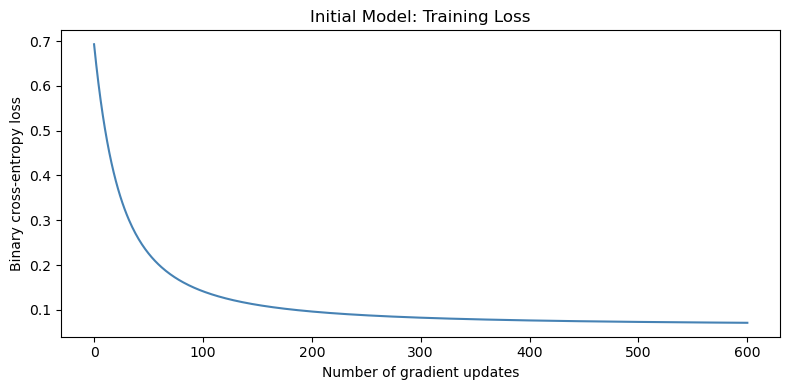

In [33]:
# Include the objective at the final updated weights.
training_losses = (
    initial_model.loss_history
    + [float(initial_model.final_loss)]
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    range(len(training_losses)),
    training_losses,
    color="steelblue"
)

ax.set_title("Initial Model: Training Loss")
ax.set_xlabel("Number of gradient updates")
ax.set_ylabel("Binary cross-entropy loss")

plt.tight_layout()
plt.show()


The training loss falls quickly in the early updates and then levels off, which means each further update brings a smaller improvement. The curve shows no obvious oscillation or divergence. Even so, training loss alone can't show that the model has converged or that it can pick out bestsellers, so I will assess validation performance next.

### Initial Validation Performance and Baseline Comparison

In [34]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    log_loss,
    confusion_matrix
)

# Evaluation functions follow scikit-learn's metric documentation.
# Only our scratch implementation is used to train the model.
def evaluate_predictions(name, actual, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "model": name,
        "threshold": threshold,
        "predicted_bestsellers": int(predictions.sum()),
        "accuracy": accuracy_score(actual, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            actual, predictions
        ),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            actual, predictions, zero_division=0
        ),
        "average_precision": average_precision_score(
            actual, probabilities
        ),
        "ROC_AUC": roc_auc_score(actual, probabilities),
        "log_loss": log_loss(actual, probabilities)
    }


# Score validation books using the initial trained model.
initial_validation_probabilities = (
    initial_model.predict_probability(X_validation)
)

# Baseline: assign every book the training bestseller prevalence.
# At threshold 0.5, this predicts every book as the majority class.
baseline_validation_probabilities = np.full(
    len(y_validation),
    y_train.mean()
)

initial_validation_results = pd.DataFrame([
    evaluate_predictions(
        "Majority / prevalence baseline",
        y_validation,
        baseline_validation_probabilities
    ),
    evaluate_predictions(
        "Initial scratch model",
        y_validation,
        initial_validation_probabilities
    )
])

display(initial_validation_results.round(4))

,model,threshold,predicted_bestsellers,accuracy,balanced_accuracy,precision,recall,F1,average_precision,ROC_AUC,log_loss
0,Majority / prevalence baseline,0.5,0,0.9875,0.5,0.0,0.0,0.0,0.0125,0.500,0.0672
1,Initial scratch model,0.5,0,0.9875,0.5,0.0,0.0,0.0,0.0239,0.626,0.0702


At a threshold of 0.5, the model does not predict a single bestseller. Its accuracy of 98.75% is the same as the baseline's, but its recall and F1 are both zero. That high accuracy comes from the class imbalance and not from the model detecting anything.

The model does show some modest ability to rank bestsellers higher: its average precision is 0.0239 against the baseline's 0.0125, and its ROC-AUC is 0.626. Its log loss, however, is worse (0.0702 versus 0.0672). Next, I will evaluate other training configurations and a threshold chosen on the validation set.

In [35]:
initial_validation_predictions = (
    initial_validation_probabilities >= 0.5
).astype(int)

matrix = confusion_matrix(
    y_validation,
    initial_validation_predictions,
    labels=[0, 1]
)

display(pd.DataFrame(
    matrix,
    index=["Actual other", "Actual bestseller"],
    columns=["Predicted other", "Predicted bestseller"]
))

print(
    "Minimum predicted probability:",
    round(initial_validation_probabilities.min(), 6)
)

print(
    "Maximum predicted probability:",
    round(initial_validation_probabilities.max(), 6)
)

print(
    "Validation bestseller prevalence:",
    round(y_validation.mean(), 6)
)

,Predicted other,Predicted bestseller
Actual other,3947,0
Actual bestseller,50,0


Minimum predicted probability: 0.014655
Maximum predicted probability: 0.068303
Validation bestseller prevalence: 0.012509


At a threshold of 0.5, the model correctly classifies 3,947 non-bestsellers but misses all 50 bestsellers. Its predicted probabilities range from 1.47% to 6.83%, so none of them reaches the threshold.

Even the lowest prediction is above the observed validation prevalence of 1.25%, which suggests the model overestimates probabilities across this set. I will compare other training configurations before choosing a lower decision threshold using the validation data.

### Retraining and Hyperparameter Comparison

In [36]:
# Retain the initial model so it is not trained again.
model_candidates = {
    "Initial: lr=0.1, L2=0": initial_model
}

alternative_settings = [
    ("Alternative 1: lr=0.3, L2=0", 0.3, 0.0),
    ("Alternative 2: lr=0.1, L2=0.01", 0.1, 0.01),
    ("Alternative 3: lr=0.3, L2=0.01", 0.3, 0.01)
]

# Train every alternative on the same training data.
for name, learning_rate, l2 in alternative_settings:
    model = LogisticRegressionScratch(
        learning_rate=learning_rate,
        iterations=600,
        l2=l2,
        tolerance=1e-8
    )

    model.fit(X_train, y_train)
    model_candidates[name] = model

print("All four configurations are ready for comparison.")

All four configurations are ready for comparison.


In [37]:
comparison_rows = []

for name, model in model_candidates.items():
    probabilities = model.predict_probability(X_validation)

    row = evaluate_predictions(
        name,
        y_validation,
        probabilities,
        threshold=0.5
    )

    row.update({
        "learning_rate": model.learning_rate,
        "L2": model.l2,
        "updates": model.n_iterations,
        "final_training_objective": model.final_loss
    })

    comparison_rows.append(row)

validation_comparison = pd.DataFrame(comparison_rows)

# Apply the planned selection rule:
# highest validation AP, then lowest validation log loss.
validation_comparison = (
    validation_comparison
    .sort_values(
        ["average_precision", "log_loss"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(
    validation_comparison[[
        "model",
        "updates",
        "average_precision",
        "ROC_AUC",
        "log_loss",
        "predicted_bestsellers",
        "precision",
        "recall",
        "F1"
    ]].round(4)
)

best_model_name = validation_comparison.loc[0, "model"]
best_model = model_candidates[best_model_name]

print("Selected model:", best_model_name)

,model,updates,average_precision,ROC_AUC,log_loss,predicted_bestsellers,precision,recall,F1
0,"Alternative 1: lr=0.3, L2=0",600,0.0250,0.6268,0.0661,0,0.0,0.0,0.0
1,"Alternative 3: lr=0.3, L2=0.01",600,0.0239,0.6282,0.0662,0,0.0,0.0,0.0
2,"Initial: lr=0.1, L2=0",600,0.0239,0.6260,0.0702,0,0.0,0.0,0.0
3,"Alternative 2: lr=0.1, L2=0.01",600,0.0236,0.6260,0.0702,0,0.0,0.0,0.0


Selected model: Alternative 1: lr=0.3, L2=0


The model with a learning rate of 0.3 and no L2 penalty was chosen because it had the highest validation average precision (0.0250). Its log loss improved from 0.0702 to 0.0661, which is slightly better than the baseline's 0.0672. L2 regularisation did not improve the main selection metric.

Every configuration ran all 600 updates, and none of them predicted a bestseller at the 0.5 threshold. Ranking performance is still modest, so I will choose a lower threshold using the validation data.

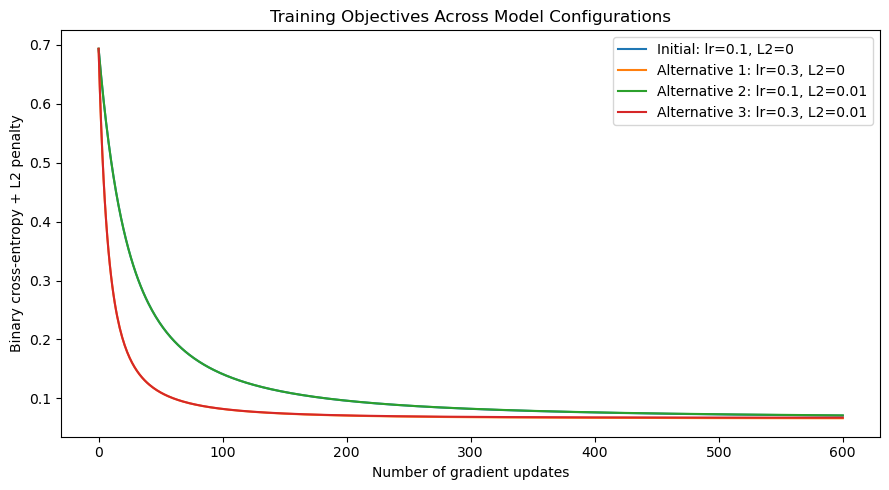

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))

for name, model in model_candidates.items():
    losses = model.loss_history + [float(model.final_loss)]

    ax.plot(
        range(len(losses)),
        losses,
        label=name
    )

ax.set_title("Training Objectives Across Model Configurations")
ax.set_xlabel("Number of gradient updates")
ax.set_ylabel("Binary cross-entropy + L2 penalty")
ax.legend()

plt.tight_layout()
plt.show()

Configurations with a learning rate of 0.3 bring the training objective down faster than those with 0.1, and there is no obvious oscillation or divergence. The curves level off as the improvements get smaller. L2 regularisation changes the objective itself, so I will choose the final model using validation metrics and not by directly comparing the penalised training losses.

### Selecting the Classification Threshold

In [39]:
from sklearn.metrics import precision_recall_curve

# Obtain validation probabilities from the selected model.
best_validation_probabilities = (
    best_model.predict_probability(X_validation)
)

# Evaluate precision and recall at each distinct score threshold.
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_validation,
        best_validation_probabilities
    )
)

# The final precision/recall pair has no corresponding threshold.
threshold_f1 = (
    2 * precision_values[:-1] * recall_values[:-1]
    / np.maximum(
        precision_values[:-1] + recall_values[:-1],
        1e-15
    )
)

# Select the threshold giving the highest validation F1.
# If tied, choose the higher threshold to flag fewer books.
best_f1 = threshold_f1.max()

best_position = np.flatnonzero(
    threshold_f1 == best_f1
)[-1]

best_threshold = float(thresholds[best_position])

print("Selected model:", best_model_name)
print("Validation-selected threshold:", best_threshold)
print("Maximum validation F1:", best_f1)

Selected model: Alternative 1: lr=0.3, L2=0
Validation-selected threshold: 0.04060967568271723
Maximum validation F1: 0.1


The threshold chosen on the validation set is about 0.04061 (4.06%), which gives a maximum validation F1 of 0.10. That is better than the F1 of zero at a threshold of 0.5, although performance is still weak. I will fix the threshold at its full calculated precision before the final test evaluation.

In [40]:
threshold_comparison = pd.DataFrame([
    evaluate_predictions(
        "Selected model: default threshold",
        y_validation,
        best_validation_probabilities,
        threshold=0.5
    ),
    evaluate_predictions(
        "Selected model: tuned threshold",
        y_validation,
        best_validation_probabilities,
        threshold=best_threshold
    )
])

display(
    threshold_comparison[[
        "model",
        "threshold",
        "predicted_bestsellers",
        "precision",
        "recall",
        "F1",
        "balanced_accuracy",
        "average_precision",
        "ROC_AUC"
    ]].round(4)
)

# Show the actual numbers of correct predictions and errors.
validation_predictions = (
    best_validation_probabilities >= best_threshold
).astype(int)

display(pd.DataFrame(
    confusion_matrix(
        y_validation,
        validation_predictions,
        labels=[0, 1]
    ),
    index=["Actual other", "Actual bestseller"],
    columns=["Predicted other", "Predicted bestseller"]
))

,model,threshold,predicted_bestsellers,precision,recall,F1,balanced_accuracy,average_precision,ROC_AUC
0,Selected model: default threshold,0.5000,0,0.0000,0.00,0.0,0.5000,0.025,0.6268
1,Selected model: tuned threshold,0.0406,90,0.0778,0.14,0.1,0.5595,0.025,0.6268


,Predicted other,Predicted bestseller
Actual other,3864,83
Actual bestseller,43,7


At the tuned threshold, the model flags 90 validation books. Of these, 7 are real bestsellers and 83 are false positives, and it misses 43 of the 50 actual bestsellers. Precision is 7.78%, recall is 14% and F1 is 0.10, so the model is of limited practical use.

Average precision and ROC-AUC stay the same, because tuning the threshold only changes the class labels and not the underlying probabilities. The final performance will be assessed on the untouched test set.

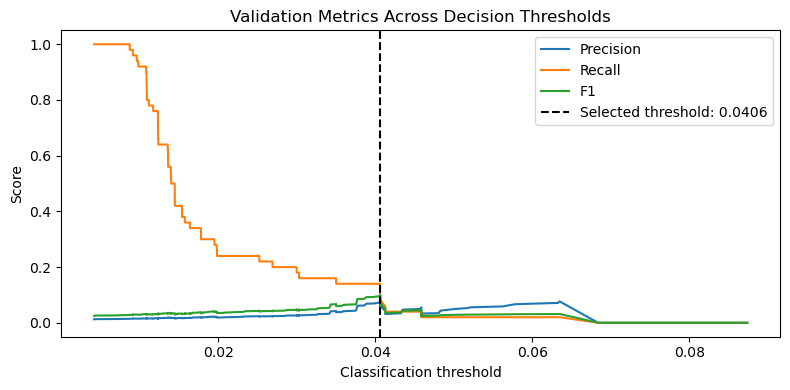

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    thresholds,
    precision_values[:-1],
    label="Precision"
)

ax.plot(
    thresholds,
    recall_values[:-1],
    label="Recall"
)

ax.plot(
    thresholds,
    threshold_f1,
    label="F1"
)

ax.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label=f"Selected threshold: {best_threshold:.4f}"
)

ax.set_title("Validation Metrics Across Decision Thresholds")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.legend()

plt.tight_layout()
plt.show()

Recall drops as the threshold goes up, while precision moves up and down and stays low. A threshold of about 0.0406 gives the highest validation F1, but none of the thresholds I tested achieves both high precision and high recall. Adjusting the threshold only changes the balance between the two types of error, and it does not fix the model's limited ability to tell the classes apart.

## d) Final Test Evaluation

### Test Metrics and Confusion Matrix

In [42]:
# Keep the model and full-precision threshold selected on validation data.
final_model = best_model
final_threshold = best_threshold

# Score the test set without fitting or changing any parameters.
test_probabilities = final_model.predict_probability(X_test)

# Baseline probabilities use training prevalence, not test prevalence.
baseline_test_probabilities = np.full(
    len(y_test),
    y_train.mean()
)

test_results = pd.DataFrame([
    evaluate_predictions(
        "Majority / prevalence baseline",
        y_test,
        baseline_test_probabilities,
        threshold=0.5
    ),
    evaluate_predictions(
        "Selected model: default threshold",
        y_test,
        test_probabilities,
        threshold=0.5
    ),
    evaluate_predictions(
        "Selected model: validation-tuned threshold",
        y_test,
        test_probabilities,
        threshold=final_threshold
    )
])

display(test_results.round(4))

print("Final model:", best_model_name)
print("Frozen threshold:", final_threshold)
print("Test records:", len(y_test))
print("Actual test bestsellers:", int(y_test.sum()))

,model,threshold,predicted_bestsellers,accuracy,balanced_accuracy,precision,recall,F1,average_precision,ROC_AUC,log_loss
0,Majority / prevalence baseline,0.5000,0,0.9813,0.500,0.0000,0.0000,0.0000,0.0187,0.5000,0.0941
1,Selected model: default threshold,0.5000,0,0.9813,0.500,0.0000,0.0000,0.0000,0.0446,0.6888,0.0895
2,Selected model: validation-tuned threshold,0.0406,86,0.9623,0.523,0.0581,0.0667,0.0621,0.0446,0.6888,0.0895


Final model: Alternative 1: lr=0.3, L2=0
Frozen threshold: 0.04060967568271723
Test records: 4006
Actual test bestsellers: 75


On the untouched test set, the model reaches an average precision of 0.0446 against the baseline's 0.0187, a ROC-AUC of 0.6888 and a better log loss (0.0895 versus 0.0941), which points to some predictive signal.

At the frozen threshold of about 0.0406, though, precision is only 5.81%, recall is 6.67% and F1 is 0.0621. Just 5 of the 75 bestsellers are found among the 86 books flagged. So even though the model beats the baseline on the ranking metrics, it has limited practical use.

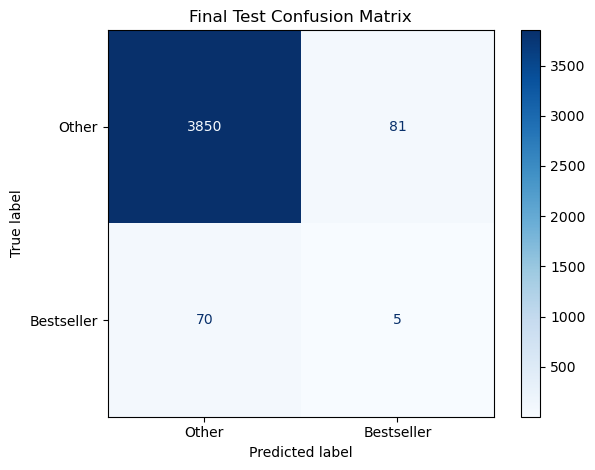

True negatives: 3850
False positives: 81
False negatives: 70
True positives: 5


In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

# Apply the validation-selected threshold unchanged.
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

test_matrix = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=test_matrix,
    display_labels=["Other", "Bestseller"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = test_matrix.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

The model correctly identifies 3,850 non-bestsellers and 5 bestsellers, but it produces 81 false positives and misses 70 bestsellers. For the press, these errors mean marketing effort that may be wasted and opportunities that may be missed. The model is therefore not suitable as the only basis for publishing or promotional decisions.

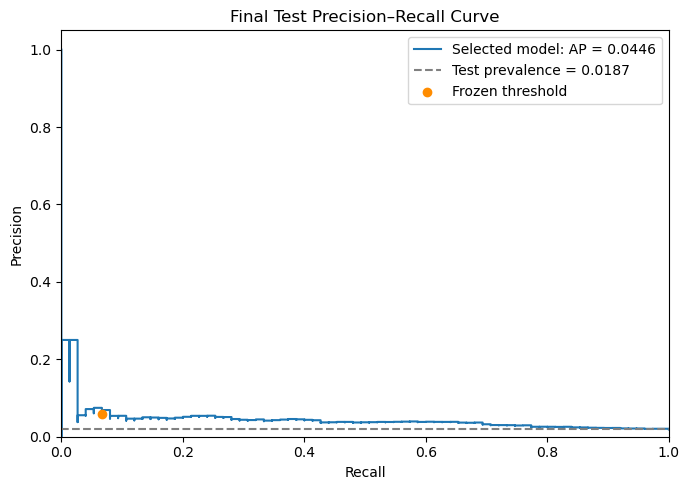

In [44]:
test_precision, test_recall, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

test_ap = average_precision_score(
    y_test,
    test_probabilities
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.step(
    test_recall,
    test_precision,
    where="post",
    label=f"Selected model: AP = {test_ap:.4f}"
)

ax.axhline(
    y_test.mean(),
    color="grey",
    linestyle="--",
    label=f"Test prevalence = {y_test.mean():.4f}"
)

# Mark the operating point chosen using validation data.
ax.scatter(
    recall_score(y_test, test_predictions),
    precision_score(
        y_test, test_predictions, zero_division=0
    ),
    color="darkorange",
    label="Frozen threshold",
    zorder=3
)

ax.set_title("Final Test Precision–Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()
plt.show()

Test average precision is 0.0446, which is above the prevalence baseline of 0.0187. Even so, precision stays low across most recall levels. The frozen threshold picks out only a small share of the bestsellers, which confirms that the model gives some information for ranking books but detects bestsellers poorly in practice.

### Interpreting the Model Coefficients

In [45]:
# The first coefficient belongs to the intercept.
print("Intercept:", round(float(final_model.weights[0]), 4))

# Coefficients describe changes in log-odds for standardised predictors.
coefficient_table = pd.DataFrame({
    "feature": selected_features,
    "coefficient": final_model.weights[1:],
    "training_standard_deviation": training_stds
})

# Odds multiplier for a one-training-standard-deviation increase.
coefficient_table["odds_ratio_per_SD"] = np.exp(
    coefficient_table["coefficient"]
)

# For binary indicators, also calculate the odds multiplier
# for changing the original value from 0 to 1.
binary_features = [
    "category_missing",
    *subjects.keys()
]

coefficient_table["odds_ratio_0_to_1"] = np.where(
    coefficient_table["feature"].isin(binary_features),
    np.exp(
        coefficient_table["coefficient"]
        / coefficient_table["training_standard_deviation"]
    ),
    np.nan
)

coefficient_table = coefficient_table.sort_values(
    "coefficient",
    ascending=False
)

display(coefficient_table.round(4))

Intercept: -4.3145


,feature,coefficient,training_standard_deviation,odds_ratio_per_SD,odds_ratio_0_to_1
9,health,0.2919,0.2798,1.3390,2.8388
1,log_categories,0.2370,0.5388,1.2674,NaN
5,business,0.1406,0.2560,1.1510,1.7320
3,fiction,0.0902,0.3149,1.0944,1.3318
4,children,0.0402,0.3223,1.0411,1.1329
0,title_chars,-0.0014,30.2287,0.9986,NaN
6,religion,-0.0164,0.3177,0.9837,0.9496
8,science,-0.0541,0.2400,0.9473,0.7981
2,category_missing,-0.1012,0.2124,0.9037,0.6208
7,history,-0.1139,0.2646,0.8924,0.6503


With the other predictors held constant, books recorded under health and business are associated with roughly 2.84 and 1.73 times the estimated odds of being a bestseller, respectively. Books recorded under computers are associated with lower odds (an odds ratio of 0.48). Title length has a coefficient close to zero.

These are fitted associations only. They are not causal effects, and they are not evidence of statistical significance. The NaN values in 'odds ratio 0 to 1' appear because that binary comparison doesn't apply to the continuous predictors.

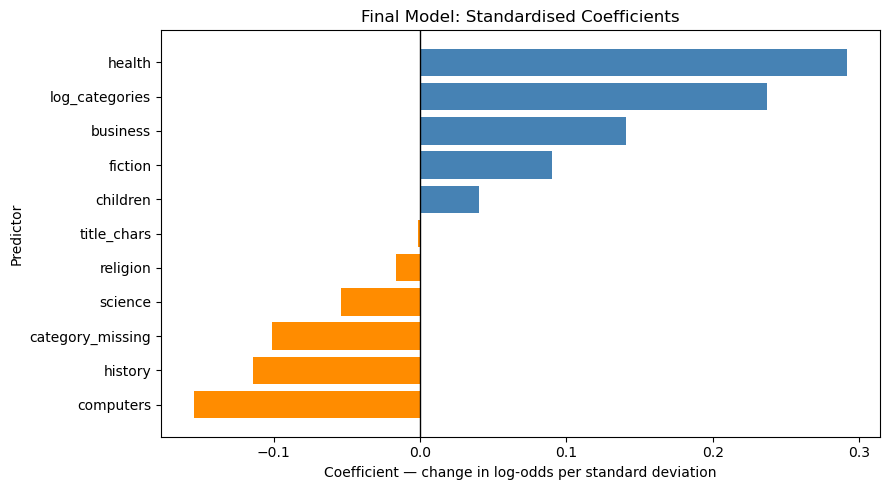

In [46]:
coefficient_plot = coefficient_table.sort_values("coefficient")

colors = [
    "steelblue" if value >= 0 else "darkorange"
    for value in coefficient_plot["coefficient"]
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    coefficient_plot["feature"],
    coefficient_plot["coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("Final Model: Standardised Coefficients")
ax.set_xlabel("Coefficient — change in log-odds per standard deviation")
ax.set_ylabel("Predictor")

plt.tight_layout()
plt.show()

Health membership and the log-transformed category count have the largest positive standardised coefficients, while computer membership has the most negative one. Once the other predictors are accounted for, title length has a near-zero association. These fitted associations do not show cause and effect or statistical significance.